In [1]:
%pip install -r requirements-offline.txt --quiet

/Users/utarn/projects/datascience-metrology/.check-env/bin/python: No module named pip


Note: you may need to restart the kernel to use updated packages.


# Solution — Module M7: ทำงานอัตโนมัติ

เปิดเผยหลังจบแล็บ — เทียบกับของตัวเอง โฟกัสที่โครงสร้างลูปและการเขียนไฟล์

In [2]:
import pandas as pd
from pathlib import Path


def repo_root() -> Path:
    """หา repo root โดยไล่ขึ้นจาก cwd."""
    for p in (Path.cwd(), *Path.cwd().parents):
        if (p / "requirements-offline.txt").exists():
            return p
    raise SystemExit(
        "ไม่พบ repo root — เปิด JupyterLab จาก repo root (uv run jupyter lab)")

DATA = repo_root() / "datasets"

pm25 = pd.read_csv(DATA / "pcd_pm25_2025"
                   / "pm25_daily_2025_15stations.csv")
pm25["date"] = pd.to_datetime(pm25["observation_date"])

## ส่วนที่ 1 — เตรียมเทมเพลต (1 สถานี)

In [3]:
pm25["month"] = pm25["date"].dt.month

one = pm25[pm25["station_code"] == "05T"]
summary = one.groupby("month").agg(
    mean_pm25=("measured_value", "mean"),
    max_pm25=("measured_value", "max"),
)
summary.round(1).head(4)

,mean_pm25,max_pm25
month,,
1,42.8,73.7
2,34.7,64.1
3,28.6,65.2
4,17.8,30.8


**1.1** ดูตาราง: เดือนที่ max สูงสุด (ราวมี.ค.–เม.ย. — ฤดูเผา) mean
ของเดือนนั้นก็สูงสุดด้วย แต่มีเดือนที่ max สูงลอย ๆ จากเหตุการณ์วันเดียว
ทั้งที่ mean ธรรมดา — นี่คือเหตุผลที่รายงานคุณภาพอากาศต้องรายงานทั้ง
"ระดับปกติ" (mean) และ "วันแย่ที่สุด" (max) คนละความหมาย

## ส่วนที่ 2 — วนทุกสถานี เขียนไฟล์อัตโนมัติ

In [4]:
outputs = Path("outputs")
outputs.mkdir(exist_ok=True)

for code, group in pm25.groupby("station_code"):
    summary = group.groupby("month").agg(
        mean_pm25=("measured_value", "mean"),
        max_pm25=("measured_value", "max"),
    )
    summary.round(1).to_csv(outputs / f"station_{code}.csv")

print(f"เขียนแล้ว {len(list(outputs.glob('station_*.csv')))} ไฟล์")

เขียนแล้ว 15 ไฟล์


**2.1** ศูนย์จุด — ลูปวนตามจำนวนกลุ่มที่ข้อมูลมีเอง สคริปต์เดิม
รองรับข้อมูลโตได้ทันที (สิ่งที่ต้องเปลี่ยนคือหน้าจอไม่พอแสดงไฟล์ทั้งหมด)

## ส่วนที่ 3 — อ่านกลับมารวม

In [5]:
frames = []
for path in sorted(outputs.glob("station_*.csv")):
    one = pd.read_csv(path)
    one["station"] = path.stem.removeprefix("station_")
    frames.append(one)

combined = pd.concat(frames, ignore_index=True)
print(f"ได้ {len(combined):,} แถว × {combined.shape[1]} คอลัมน์")

ได้ 180 แถว × 4 คอลัมน์


**3.1** เพราะการแตกและการรวมเป็นการย้ายแถวที่**ไม่กรองไม่สรุป** —
แต่ละไฟล์เก็บทุกแถวของสถานีตัวเอง (365 × 15 = 5,475) และ concat นำกลับครบ
สิ่งที่ทำให้แถวหายได้คือการกรอง/ตัดซ้ำระหว่างทาง — จึงต้องเช็คจำนวนแถว
ก่อน-หลังเป็นนิสัย (ข้อนี้มาจาก M3)

## ส่วนที่ 4 — กราฟอัตโนมัติ

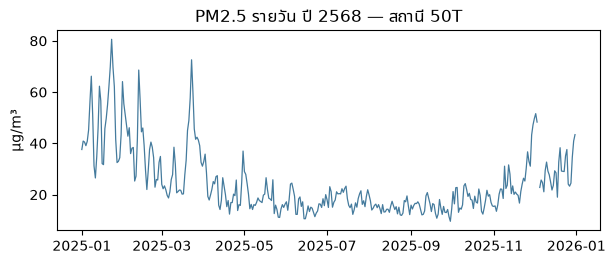

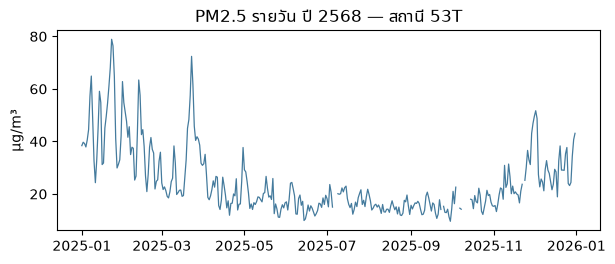

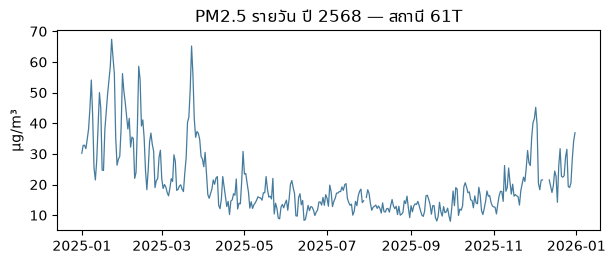

In [6]:
import matplotlib.pyplot as plt  # noqa: E402

plt.rcParams["font.family"] = [
    "DejaVu Sans", "Noto Sans Thai", "Leelawadee UI", "Tahoma",
]

for code in ["50T", "53T", "61T"]:
    one = pm25[pm25["station_code"] == code]
    fig, ax = plt.subplots(figsize=(7, 2.6))
    ax.plot(one["date"], one["measured_value"], color="#457b9d",
            lw=0.9)
    ax.set_title(f"PM2.5 รายวัน ปี 2568 — สถานี {code}")
    ax.set_ylabel("µg/m³")
    plt.savefig(outputs / f"chart_{code}.png", dpi=120,
                bbox_inches="tight")
    plt.show()

**4.1** จังหวะฤดูคล้ายกัน (สูงช่วงต้นปี ต่ำกลางปี — ฤดูเผาก่อนฝน) —
แต่ระดับความรุนแรงต่างกันตามพื้นที่ สำหรับการแจ้งเตือน ควรใช้ค่าดิบหรือ
moving average สั้น (เช่น 3-7 วัน) เพราะการเตือนต้อง**เร็วกว่า**ที่เส้นเรียบ
จะตอบสนอง — ย้ำบทเรียน M6: ความกว้างของหน้าต่าง = การเลือกเร็ว vs นิ่ง